# HW3: Hyperparameter Tuning

This notebook trains a baseline classifier on the chest X-ray dataset to distinguish **NORMAL** from **PNEUMONIA** images.

It is organized as follows: import libraries → define training / validation / test functions → prepare data → build model → set hyperparameters and train → plot learning curves → evaluate on the test set.

Use this notebook as a starting point. You are free to modify any part of it (hyperparameters, model architecture, data augmentation, etc.) for your experiments, and summarize your findings in the analysis report.




# Import Library

In [ ]:
# Original matplotlib / numpy / random / torch / nn / optim / DataLoader / torchvision imports retained.
import matplotlib.pyplot as plt
import numpy as np
import random
import time
import torch
import torch.nn as nn
import torch.optim as optims

from sklearn.metrics import accuracy_score
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.transforms.functional import InterpolationMode

# [ADDED] Only the libraries needed for robust split, sampling, evaluation, and experiment logs.
import os, re, json, copy, zipfile, csv
from collections import Counter
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, WeightedRandomSampler
from sklearn.model_selection import train_test_split
from sklearn.metrics import balanced_accuracy_score, confusion_matrix, roc_auc_score, average_precision_score


This cell sets up the computing device and checks whether a GPU is available. Training on a GPU is much faster than on a CPU.

In [ ]:
# [MODIFIED — teacher's original Cell 04: Device]
# Original: torch.device('cuda') crashed on machines without CUDA.
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
gpu_count = torch.cuda.device_count()
print("Using", gpu_count, "GPUs")
print("CUDA is available:", torch.cuda.is_available())
print("Selected device:", device)

SEED = 2026

def seed_all(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_all()
# Good for small CPU training; adjust as desired on GPU.
if device.type == 'cpu':
    torch.set_num_threads(min(4, os.cpu_count() or 1))


This cell keeps the teacher's **three functions and their roles** (`train_one_epoch`, `val_one_epoch`, `evaluate`).

**修改（原始 Cell 06）**：對樣本數加權計算 epoch loss / accuracy（避免最後不足一整個 batch 被等權重）；不再依整體 accuracy 決定 checkpoint，而是根據 validation AUROC，並在輸出提供 balanced accuracy、sensitivity、specificity、confusion matrix 等。`BCEWithLogitsLoss` 對應無 Sigmoid 的模型輸出，metrics 用 sigmoid 還原機率。

- `train_one_epoch`: same forward → loss → backward → optimizer step pattern.
- `val_one_epoch`: no gradient updates; save best **validation AUROC** checkpoint.
- `evaluate`: load only the saved checkpoint to evaluate the held-out test set. Never silently evaluate an untrained random model.


In [ ]:
# The original function names and training-loop structure are preserved.

def score_binary(y_true, y_probability):
    """[ADDED] Robust metrics; class 1 = PNEUMONIA."""
    y_true = np.asarray(y_true, dtype=int)
    y_probability = np.asarray(y_probability, dtype=float)
    pred = (y_probability >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return dict(
        accuracy=float(accuracy_score(y_true, pred)),
        balanced_accuracy=float(balanced_accuracy_score(y_true, pred)),
        sensitivity=float(tp / (tp + fn)) if (tp + fn) else None,
        specificity=float(tn / (tn + fp)) if (tn + fp) else None,
        auroc=float(roc_auc_score(y_true, y_probability)) if len(set(y_true)) == 2 else None,
        average_precision=float(average_precision_score(y_true, y_probability)) if len(set(y_true)) == 2 else None,
        tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp)
    )

# train loop — same signature as teacher's version.
def train_one_epoch(model, device, criterion, optimizer, train_data_loader):
    start_time = time.time()
    model.train()
    epoch_loss = 0.0
    total = 0
    correct = 0

    for batch_idx, (images, labels) in enumerate(train_data_loader):
        images = images.to(device)
        labels = labels.to(device).float().view(-1)
        optimizer.zero_grad(set_to_none=True)
        logits = model(images).view(-1)   # [MODIFIED] logits, not sigmoid probabilities
        loss = criterion(logits, labels)

        # Calculating Loss & Metrics — weight each batch by its sample size.
        epoch_loss += loss.item() * len(labels)
        correct += ((logits.detach() >= 0).float() == labels).sum().item()
        total += len(labels)

        # Backpropagation — unchanged teacher logic.
        loss.backward()
        optimizer.step()

    total_time = time.time() - start_time
    return epoch_loss / total, (correct / total) * 100, total_time

# validation loop — original function name retained.
def val_one_epoch(model, device, criterion, val_data_loader, best_auc, save):
    start_time = time.time()
    model.eval()
    total_loss, n = 0.0, 0
    all_probs, all_labels = [], []

    with torch.no_grad():
        for images, labels in val_data_loader:
            images = images.to(device)
            labels = labels.to(device).float().view(-1)
            logits = model(images).view(-1)
            loss = criterion(logits, labels)
            total_loss += loss.item() * len(labels)
            n += len(labels)
            all_probs.extend(torch.sigmoid(logits).cpu().tolist())
            all_labels.extend(labels.cpu().tolist())

    epoch_loss = total_loss / n
    metrics = score_binary(all_labels, all_probs)
    epoch_acc = metrics['accuracy'] * 100

    # Saving best model by validation AUROC (NOT test accuracy).
    auc = metrics['auroc']
    if auc is None:
        raise ValueError('Validation split needs both NORMAL and PNEUMONIA for AUROC.')
    if auc > best_auc + 1e-10:
        best_auc = auc
        torch.save(model.state_dict(), f'{save}.pth')

    return epoch_loss, epoch_acc, time.time() - start_time, best_auc, metrics

# evaluate loop — original function name retained; refuses to use random weights.
def evaluate(model, device, model_path, test_loader, criterion):
    model_path = Path(model_path)
    if not model_path.is_file():
        raise FileNotFoundError(f'Trained model checkpoint missing: {model_path}')
    model.load_state_dict(torch.load(model_path, map_location=device, weights_only=True))
    print('Model weights loaded successfully:', model_path)
    model.to(device)
    model.eval()
    total_loss, n = 0.0, 0
    all_probs, all_labels = [], []

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            labels = labels.to(device).float().view(-1)
            logits = model(images).view(-1)
            loss = criterion(logits, labels)
            total_loss += loss.item() * len(labels)
            n += len(labels)
            all_probs.extend(torch.sigmoid(logits).cpu().tolist())
            all_labels.extend(labels.cpu().tolist())

    if not n:
        raise ValueError('Test set is empty; inspect the dataset split.')
    results = score_binary(all_labels, all_probs)
    results.update(loss=total_loss / n, n=n)
    print('Test accuracy: %.2f%%; balanced accuracy: %.2f%%; AUROC: %.4f' %
          (100 * results['accuracy'], 100 * results['balanced_accuracy'], results['auroc']))
    print('Confusion matrix: TN=%d FP=%d FN=%d TP=%d' %
          (results['tn'], results['fp'], results['fn'], results['tp']))
    return results['loss'], results['accuracy'] * 100, results


# Data Preparation

Original Cell 09 mounted Google Drive unconditionally. **修改**：先使用當前資料夾內的 `chest_xray_HW3*.zip`（本機或 Colab 都可）；如果你把 ZIP 放在 Google Drive，可以把 `USE_GOOGLE_DRIVE=True` 並修改 `DATA_ZIP` 路徑。不用 Drive 時不會再因 `google.colab` 無法匯入而中斷。


In [ ]:
USE_GOOGLE_DRIVE = False  # Set True only in Google Colab when ZIP lives in Google Drive.
if USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive/')

ROOT = Path.cwd()
DATA_ROOT = ROOT / 'chest_xray_HW3'
DATA_ZIP = None  # Alternatively: Path('/content/drive/MyDrive/your/chest_xray_HW3.zip')
if not DATA_ROOT.exists():
    if DATA_ZIP is None:
        zips = sorted(ROOT.glob('chest_xray_HW3*.zip'))
        if not zips and Path('/mnt/data').exists():
            zips = sorted(Path('/mnt/data').glob('chest_xray_HW3*.zip'))
        if not zips:
            raise FileNotFoundError('Put chest_xray_HW3-...zip next to this notebook (or set DATA_ZIP).')
        DATA_ZIP = zips[0]
    with zipfile.ZipFile(DATA_ZIP) as archive:
        archive.extractall(ROOT)
    print('Extracted:', DATA_ZIP)
assert DATA_ROOT.is_dir(), f'Dataset root not found: {DATA_ROOT}'
print('Dataset root:', DATA_ROOT)

RESULTS_DIR = ROOT / 'results_annotated'
RESULTS_DIR.mkdir(exist_ok=True)


Mounted at /content/drive/


Original Cell 11: define `train_path`, `test_path`, `val_path`; `train_transform` / `common_transform`; then `train_dataset` / `val_dataset` / `test_dataset` and their DataLoaders.

**修改原因（必要而非隨意改寫）**：提供的 ZIP 中 `test` 沒有影像，而 `val` 只有 8 張 NORMAL。直接使用老師範例的三個路徑，會讓 test evaluation 無法計算、validation accuracy 無法評估 PNEUMONIA。因此只對**這一份資料集**採用以推定病人編號為群組的分層重新切分；並採用 train-only weighted sampling，降低 26 vs 540 的不平衡。訓練流程中 `train_transform` 和 `common_transform` 的用途與老師相同。

**注意**：NORMAL 檔名無可靠病人 ID、影像可能存在來源偏差，因此這不是可證明完全無病人洩漏的臨床資料集。Split manifest 會完整保存。


In [ ]:
# [MODIFIED — teacher's original Cell 11: Data Preparation]
# ① Folder paths (same names as teacher's code).
train_path = DATA_ROOT / 'train'
test_path  = DATA_ROOT / 'test'
val_path   = DATA_ROOT / 'val'

# ② Original Resize → Grayscale → ToTensor concept preserved.
# 96 instead of original 256: controlled runtime reduction for small-data experiments.
IMAGE_SIZE = 96
train_transform = transforms.Compose([
    transforms.ToTensor(),  # Resize/Grayscale are performed once in pixel cache below.
])
common_transform = transforms.Compose([
    transforms.ToTensor(),
])

# [ADDED] Alternative train-only augmentation settings used in section 5.
def make_train_transform(name='none'):
    if name == 'mild':
        return transforms.Compose([
            transforms.RandomAffine(degrees=5, translate=(0.02, 0.02), fill=0),
            transforms.ColorJitter(brightness=0.08, contrast=0.08),
            transforms.ToTensor(),
        ])
    if name == 'flip':
        return transforms.Compose([transforms.RandomHorizontalFlip(p=0.5), transforms.ToTensor()])
    if name == 'strong':
        return transforms.Compose([
            transforms.RandomAffine(degrees=20, translate=(0.12, 0.12), scale=(0.8, 1.2), fill=0),
            transforms.ColorJitter(brightness=0.3, contrast=0.3),
            transforms.ToTensor(),
        ])
    if name != 'none':
        raise ValueError('Unknown augmentation: '+name)
    return train_transform

# [ADDED] Source dataset audit. Folder names NORMAL / PNEUMONIA still drive the labels.
original_counts = {}
records = []
for split in ('train', 'val', 'test'):
    for label_name in ('NORMAL', 'PNEUMONIA'):
        files = sorted((DATA_ROOT / split / label_name).glob('*.jpeg'))
        original_counts[f'{split}/{label_name}'] = len(files)
        for p in files:
            if label_name == 'PNEUMONIA':
                match = re.match(r'(person\d+)', p.name)
                group = match.group(1) if match else p.stem
            else:
                group = p.stem  # No validated NORMAL patient IDs; limitation explicitly noted.
            records.append(dict(path=str(p), original_split=split,
                                label=int(label_name == 'PNEUMONIA'),
                                group=label_name+'_'+group, name=p.name))
print('Original image counts:', original_counts)
assert len(records) > 0, 'No input JPEG images found.'
assert len({x['path'] for x in records}) == len(records)

# [ADDED] Split by inferred group *within class*, not by individual images.
parts = {'train': [], 'val': [], 'test': []}
for label in (0, 1):
    groups = sorted({r['group'] for r in records if r['label'] == label})
    train_groups, other_groups = train_test_split(
        groups, test_size=0.30, random_state=SEED+label)
    val_groups, test_groups = train_test_split(
        other_groups, test_size=0.50, random_state=SEED+label)
    for partition, target_groups in [('train', train_groups), ('val', val_groups), ('test', test_groups)]:
        selected = set(target_groups)
        parts[partition].extend(r for r in records if r['label'] == label and r['group'] in selected)
for part in parts:
    parts[part].sort(key=lambda r: r['path'])
    print(f'{part}:', dict(Counter(r['label'] for r in parts[part])))
for a, b in [('train','val'), ('train','test'), ('val','test')]:
    assert {r['group'] for r in parts[a]}.isdisjoint({r['group'] for r in parts[b]})
    assert {r['path'] for r in parts[a]}.isdisjoint({r['path'] for r in parts[b]})
assert all({r['label'] for r in parts[k]} == {0,1} for k in parts)

# [ADDED] Cache the teacher's Resize(BICUBIC), Grayscale preprocessing once.
# (Transform on cached grayscale PIL image then only ToTensor / augment during training.)
pixel_cache = {}
for record in records:
    with Image.open(record['path']) as img:
        pixel_cache[record['path']] = img.convert('L').resize(
            (IMAGE_SIZE, IMAGE_SIZE), Image.Resampling.BICUBIC).copy()

class XrayDataset(Dataset):
    def __init__(self, recs, transform):
        self.records = recs
        self.transform = transform
    def __len__(self):
        return len(self.records)
    def __getitem__(self, idx):
        r = self.records[idx]
        return self.transform(pixel_cache[r['path']]), torch.tensor(r['label'], dtype=torch.float32)

# ③ Dataset and DataLoader names preserved from teacher's code.
train_dataset = XrayDataset(parts['train'], train_transform)
val_dataset = XrayDataset(parts['val'], common_transform)
test_dataset = XrayDataset(parts['test'], common_transform)

# [ADDED] inverse-frequency weighted sampling only for training (NOT val/test).
def make_train_loader(dataset=train_dataset, batch_size=32):
    labels = np.array([r['label'] for r in dataset.records])
    counts = np.bincount(labels, minlength=2)
    sampler = WeightedRandomSampler(
        weights=torch.as_tensor(1.0 / counts[labels], dtype=torch.double),
        num_samples=len(labels), replacement=True,
        generator=torch.Generator().manual_seed(SEED),
    )
    return DataLoader(dataset, batch_size=batch_size, sampler=sampler, drop_last=True, num_workers=0)

BATCH_SIZE = 32  # Original 64 → 32: baseline for batch-size experiments.
train_loader = make_train_loader(train_dataset, BATCH_SIZE)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False, num_workers=0)

manifest = dict(seed=SEED, source_counts=original_counts,
                split_counts={k:dict(Counter(str(r['label']) for r in v)) for k,v in parts.items()},
                method='stratified by inferred filename groups; ~70/15/15 of groups',
                caveat='NORMAL patient identity unavailable; filename inference is unverified',
                splits={k:[dict(file=r['name'], label=r['label'], group=r['group'],
                                source_split=r['original_split']) for r in v] for k,v in parts.items()})
(RESULTS_DIR / 'split_manifest.json').write_text(json.dumps(manifest, indent=2), encoding='utf-8')


Original image counts: {'train/NORMAL': 18, 'train/PNEUMONIA': 540, 'val/NORMAL': 8, 'val/PNEUMONIA': 0, 'test/NORMAL': 0, 'test/PNEUMONIA': 0}
train: {0: 18, 1: 383}
val: {0: 4, 1: 62}
test: {0: 4, 1: 95}


# Model

The teacher's baseline MLP is kept: **Flatten → Linear(64) + BatchNorm + ReLU + Dropout(0.5), repeated for three 64-unit hidden layers → Linear(1)**.

**修改（原始 Cell 14）**：將輸入尺寸參數化為 `IMAGE_SIZE`; 將最後 `Sigmoid` 移至計算機率/指標，搭配 `BCEWithLogitsLoss`。額外提供不同 width/dropout 和 CNN 作為 Architecture 實驗選項，但原本的 MLP baseline 仍清楚可見。


In [ ]:
# [MODIFIED — teacher's original Cell 14: Model]
# Same teacher MLP (three 64-unit hidden layers, BN, ReLU, Dropout),
# now wrapped in a function so each experiment starts from a fresh model.
def make_mlp(width=64, dropout=0.5):
    return nn.Sequential(
        nn.Flatten(),
        nn.Linear(IMAGE_SIZE * IMAGE_SIZE * 1, width),
        nn.BatchNorm1d(width),
        nn.ReLU(),
        nn.Dropout(dropout),

        nn.Linear(width, width),
        nn.BatchNorm1d(width),
        nn.ReLU(),
        nn.Dropout(dropout),

        nn.Linear(width, width),
        nn.BatchNorm1d(width),
        nn.ReLU(),
        nn.Dropout(dropout),

        nn.Linear(width, 1),
        # [MODIFIED] No nn.Sigmoid() here; use nn.BCEWithLogitsLoss() in Cell 17.
    )

# [ADDED] CNN alternative for the Model Architecture comparison (20%).
def make_cnn(width=16, dropout=0.3):
    return nn.Sequential(
        nn.Conv2d(1,width,3,padding=1), nn.BatchNorm2d(width), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(width,width*2,3,padding=1), nn.BatchNorm2d(width*2), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(width*2,width*4,3,padding=1), nn.BatchNorm2d(width*4), nn.ReLU(),
        nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(dropout), nn.Linear(width*4,1),
    )

def make_model(architecture='mlp', width=64, dropout=0.5):
    if architecture == 'mlp':
        return make_mlp(width, dropout)
    if architecture == 'cnn':
        return make_cnn(width, dropout)
    raise ValueError(f'Unknown architecture: {architecture}')

# Teacher's original variable still exists.
model = make_mlp(width=64, dropout=0.5)
model.to(device)
print(model)
print('Parameter count:', sum(p.numel() for p in model.parameters()))


# Loop

Teacher's original Cell 17 specifies learning rate, weight decay, LR scheduler, epochs, optimizer, criterion and checkpoint.

**修改**：(1) 修正原版先建立 scheduler、後建立 optimizer 的錯誤；(2) criterion 改為 `BCEWithLogitsLoss` 配合 Cell 14 的 logits；(3) 原始預設 `epochs=10` 調整為可比較的實驗 baseline `6` (另外有 12-epoch 對照)，`batch=32`；(4) 為比較實驗準備 `BASE_CONFIG`，僅調整實驗目標參數，其餘固定。


In [ ]:
# [MODIFIED — teacher's original Cell 17: Hyperparameters]
lr = 0.001
weight_decay = 0.001
epochs = 6             # Original 10; matched to earlier 16-run experiment report.
batch_size = BATCH_SIZE
optimizer_name = 'adam'
scheduler_name = 'none'

# [FIX] Optimizer MUST exist before creating the LR scheduler.
optimizer = optims.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
lr_scheduler = None  # Compare 'none' versus 'cosine' in added experiments.
criterion = nn.BCEWithLogitsLoss()   # [MODIFIED] More numerically stable than Sigmoid + BCELoss.

# Save checkpoint (teacher's `save` variable retained).
save = str(RESULTS_DIR / 'baseline')
BASE_CONFIG = dict(name='baseline', architecture='mlp', width=64, dropout=0.5,
                   lr=lr, batch_size=batch_size, optimizer_name='adam',
                   weight_decay=weight_decay, epochs=epochs,
                   scheduler='none', augmentation='none')
print('Baseline settings:', BASE_CONFIG)


The teacher's Cell 19 is still the **training loop**. It now calls `train_one_epoch()` and `val_one_epoch()` from original Cell 06, and wraps the loop as `run_experiment` so the SAME training code can be used for every controlled hyperparameter comparison. The baseline is trained immediately below. **Only validation data chooses the best epoch; test is held until the final selected model.**


In [ ]:
# [MODIFIED — teacher's original Cell 19: Training loop]
# Original `for epoch in range(epochs)` logic retained within a reusable function.
def run_experiment(name='baseline', architecture='mlp', width=64, dropout=0.5,
                   lr=0.001, batch_size=32, optimizer_name='adam', weight_decay=0.001,
                   epochs=6, scheduler='none', augmentation='none'):
    # [ADDED] Reset seeds + recreate model/loader/optimizer to prevent carryover between trials.
    seed_all(SEED)
    run_model = make_model(architecture, width, dropout).to(device)
    run_train_dataset = XrayDataset(parts['train'], make_train_transform(augmentation))
    run_train_loader = make_train_loader(run_train_dataset, batch_size)
    run_val_loader = val_loader

    if optimizer_name == 'adam':
        run_optimizer = optims.Adam(run_model.parameters(), lr=lr, weight_decay=weight_decay)
    elif optimizer_name == 'adamw':
        run_optimizer = optims.AdamW(run_model.parameters(), lr=lr, weight_decay=weight_decay)
    elif optimizer_name == 'sgd':
        run_optimizer = optims.SGD(run_model.parameters(), lr=lr, momentum=0.9,
                                   weight_decay=weight_decay)
    else:
        raise ValueError('Unknown optimizer: '+optimizer_name)

    if scheduler == 'cosine':
        run_scheduler = optims.lr_scheduler.CosineAnnealingLR(
            run_optimizer, T_max=epochs, eta_min=lr*0.05)
    elif scheduler == 'none':
        run_scheduler = None
    else:
        raise ValueError('Unknown scheduler: '+scheduler)

    run_criterion = nn.BCEWithLogitsLoss()
    best_auc = -1.0
    best_epoch = None
    history = []
    checkpoint = RESULTS_DIR / name
    start = time.time()

    # The teacher's original loop structure:
    for epoch in range(epochs):
        train_loss, train_acc, train_time = train_one_epoch(
            run_model, device, run_criterion, run_optimizer, run_train_loader)
        val_loss, val_acc, val_time, new_best_auc, val_metrics = val_one_epoch(
            run_model, device, run_criterion, run_val_loader, best_auc, str(checkpoint))
        if new_best_auc > best_auc + 1e-10:
            best_epoch = epoch + 1
        best_auc = new_best_auc

        history.append(dict(epoch=epoch+1, train_loss=train_loss,
                            train_sampler_accuracy=train_acc/100,
                            val_loss=val_loss, val_accuracy=val_metrics['accuracy'],
                            val_auroc=val_metrics['auroc'],
                            val_balanced_accuracy=val_metrics['balanced_accuracy'],
                            val_sensitivity=val_metrics['sensitivity'],
                            val_specificity=val_metrics['specificity'],
                            lr=run_optimizer.param_groups[0]['lr']))
        print(f'{name} | epoch {epoch+1}/{epochs} | '
              f'train_loss {train_loss:.4f} | val_loss {val_loss:.4f} | '
              f'val_AUROC {val_metrics["auroc"]:.4f} | val_bal_acc {val_metrics["balanced_accuracy"]:.4f}')
        if run_scheduler is not None:
            run_scheduler.step()

    # Saved weights are ALWAYS best validation epoch, not necessarily last epoch.
    run_model.load_state_dict(torch.load(f'{checkpoint}.pth', map_location=device, weights_only=True))
    run_model.eval()
    best_val_metrics = score_validation_model(run_model, run_criterion)
    result = dict(name=name, architecture=architecture, width=width, dropout=dropout,
                  lr=lr, batch_size=batch_size, optimizer=optimizer_name,
                  weight_decay=weight_decay, epochs=epochs, scheduler=scheduler,
                  augmentation=augmentation,
                  parameters=sum(p.numel() for p in run_model.parameters()),
                  best_epoch=best_epoch, validation=best_val_metrics,
                  history=history, elapsed_seconds=time.time()-start)
    (RESULTS_DIR / (name+'.json')).write_text(json.dumps(result, indent=2), encoding='utf-8')
    return result

def score_validation_model(run_model, run_criterion):
    """[ADDED] Report metrics from the best saved epoch, not the last epoch."""
    labels, probs = [], []
    run_model.eval()
    with torch.no_grad():
        for images, ys in val_loader:
            logits = run_model(images.to(device)).view(-1)
            labels.extend(ys.tolist())
            probs.extend(torch.sigmoid(logits).cpu().tolist())
    return score_binary(labels, probs)

# TRAIN THE BASELINE at the same location as teacher's original Cell 19.
baseline_result = run_experiment(**BASE_CONFIG)
train_losses = [h['train_loss'] for h in baseline_result['history']]
val_losses = [h['val_loss'] for h in baseline_result['history']]
train_accuracies = [100*h['train_sampler_accuracy'] for h in baseline_result['history']]
val_accuracies = [100*h['val_accuracy'] for h in baseline_result['history']]
print('Baseline best epoch:', baseline_result['best_epoch'],
      'validation:', baseline_result['validation'])


baseline | epoch 1/6 | train_loss 0.6198 | val_loss 1.1619 | val_AUROC 0.6935 | val_bal_acc 0.5000
baseline | epoch 2/6 | train_loss 0.4958 | val_loss 0.8302 | val_AUROC 0.8185 | val_bal_acc 0.6935
baseline | epoch 3/6 | train_loss 0.3981 | val_loss 0.3699 | val_AUROC 0.9677 | val_bal_acc 0.8508
baseline | epoch 4/6 | train_loss 0.3449 | val_loss 0.2406 | val_AUROC 0.9677 | val_bal_acc 0.7500
baseline | epoch 5/6 | train_loss 0.2782 | val_loss 0.1875 | val_AUROC 1.0000 | val_bal_acc 0.8750
baseline | epoch 6/6 | train_loss 0.2318 | val_loss 0.2520 | val_AUROC 0.9758 | val_bal_acc 0.8347
Baseline best epoch: 5 validation: {'accuracy': 0.9848484848484849, 'balanced_accuracy': 0.875, 'sensitivity': 1.0, 'specificity': 0.75, 'auroc': 1.0, 'average_precision': 1.0, 'tn': 3, 'fp': 1, 'fn': 0, 'tp': 62}


# Graph

This cell plots the training and validation loss and accuracy curves over epochs. Use them to check whether the model converges and whether it is overfitting or underfitting.

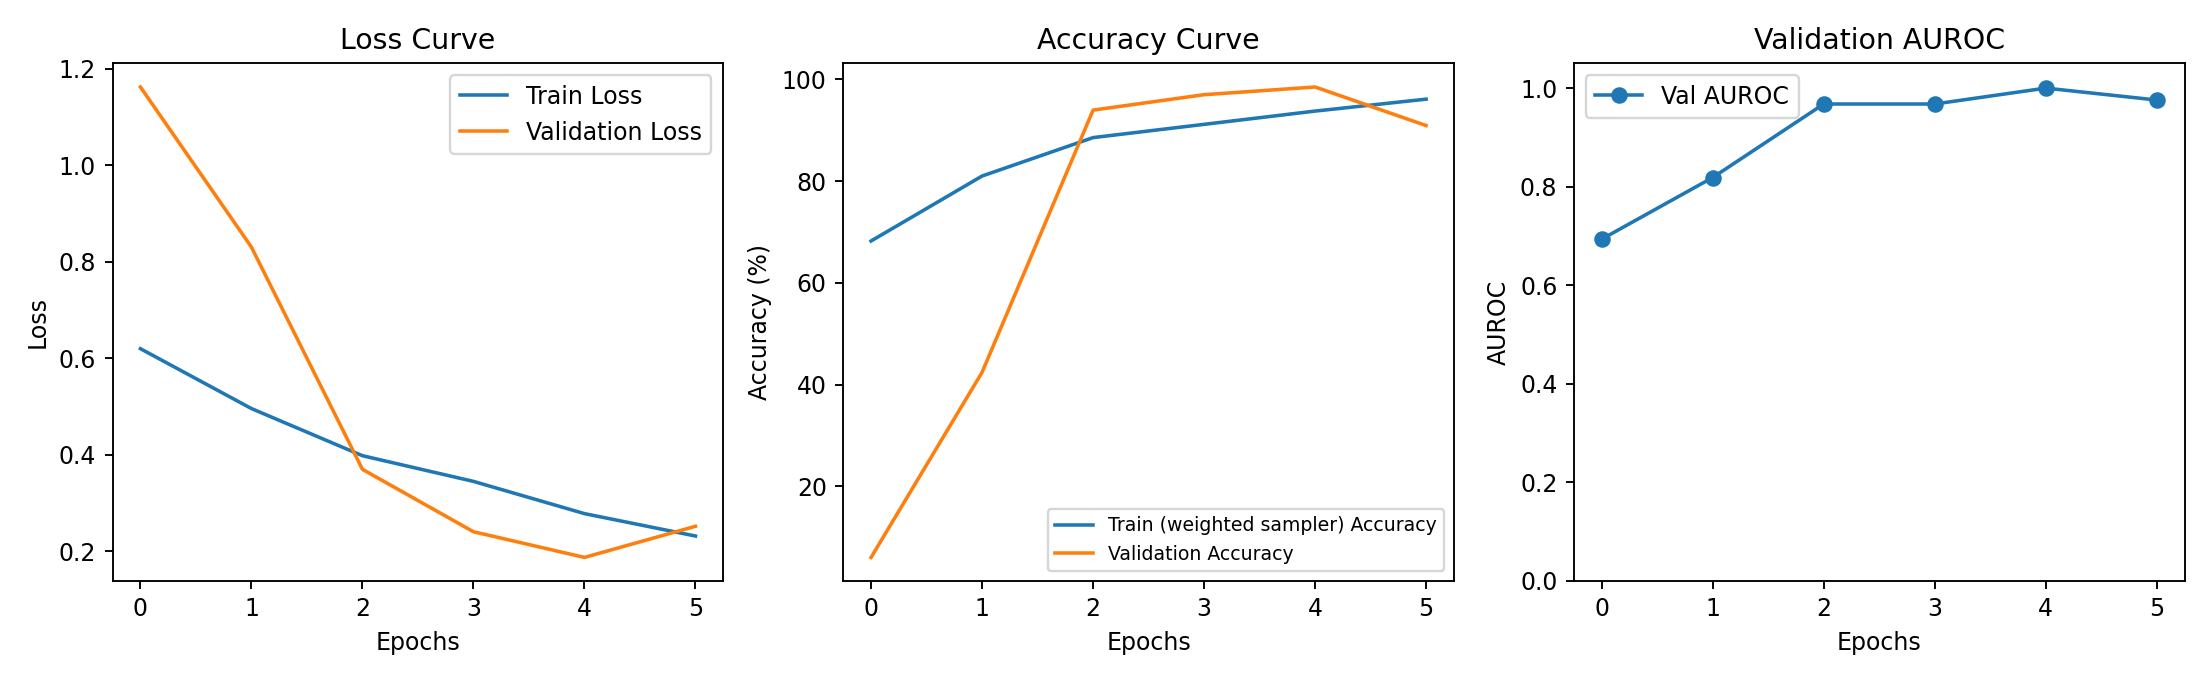

In [ ]:
# [MODIFIED — teacher's original Cell 22: Graph]
# Teacher's original 1x2 loss/accuracy graph is retained. Added AUROC and explicit labels.
plt.figure(figsize=(13, 4))
plt.subplot(1, 3, 1)
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Validation Loss')
plt.title('Loss Curve')
plt.xlabel('Epochs'); plt.ylabel('Loss'); plt.legend()

plt.subplot(1, 3, 2)
plt.plot(train_accuracies, label='Train (weighted sampler) Accuracy')
plt.plot(val_accuracies, label='Validation Accuracy')
plt.title('Accuracy Curve')
plt.xlabel('Epochs'); plt.ylabel('Accuracy (%)'); plt.legend(fontsize=8)

plt.subplot(1, 3, 3)
plt.plot([h['val_auroc'] for h in baseline_result['history']], marker='o', label='Val AUROC')
plt.title('Validation AUROC'); plt.xlabel('Epochs'); plt.ylabel('AUROC')
plt.ylim(0, 1.05); plt.legend()

plt.tight_layout()
plt.savefig(RESULTS_DIR / 'baseline_learning_curves.png', dpi=170)
plt.show()


# Evaluate

Teacher's original Cell 25 directly evaluated `model.pth`. **修改**：do NOT evaluate baseline on the held-out test set yet. Finish all validation-only comparisons first, then evaluate the **selected best configuration exactly once** in the final added Cell. This prevents test-set selection bias. The original `evaluate()` function remains available in original Cell 06.


In [ ]:
# [MODIFIED — teacher's original Cell 25: Evaluate]
# Original lines:
# model_path = 'model.pth'
# avg_test_loss, avg_test_acc = evaluate(model, device, model_path, test_loader)
# [MODIFIED] Defers held-out test evaluation until the best setting is selected on VALIDATION.
# The final added Cell calls evaluate(model, device, model_path, test_loader, criterion).
print('Test evaluation intentionally deferred: complete HW3 experiments below, then run FINAL EVALUATE cell.')
print('Current baseline was selected by val AUROC (not by test results):', baseline_result['validation'])


---
# [ADDED after teacher Cell 25] HW3 Controlled Experiments

The teacher notebook ends at original Cell 25. Everything below is *new* and maps directly to the HW3 grading rubric. We call **the same `run_experiment` (original Cell 19)** with different arguments; no independent training pipeline is substituted.

**Reading guide:** Original Cell 17 is where baseline parameters were set, original Cell 19 is the single training loop, and the following `EXPERIMENTS` table is where each comparison changes *only the parameter listed* (except SGD uses a separately disclosed learning rate). This is the main modification the original assignment asks you to understand.

| Section | Change relative to baseline | Comparison |
|---|---|---|
| Optimization 15% | original Cell 17 `lr`, `batch_size`, `optimizer_name` | `0.0001` / `0.01`, batch `16`, SGD / AdamW |
| Schedule 15% | original Cell 17 `epochs`, `weight_decay`, `scheduler_name` | `12` epochs, cosine, `0` / `0.05` wd |
| Architecture 20% | original Cell 14 model | MLP width 32, dropout 0.1, CNN |
| Augmentation 20% | original Cell 11 train_transform only | mild geometry + contrast, horizontal flip, stronger geometry |

**Fairness note:** The augmentation experiment compares three CNN variants **against the same CNN without augmentation**; the MLP optimization experiments compare against the MLP baseline. Exactly the same inferred group split is used in all runs. `train_sampler_accuracy` is accuracy on a balanced *resampled training stream*, so it should not be interpreted as natural-prevalence train accuracy.

In [ ]:
# [ADDED] All 15 additional configurations, each relative to its matching control.
# run_experiment() is exactly the original Cell 19 training loop, reused without duplication.
EXPERIMENTS = [
    # Optimization (teacher's original Cell 17: learning rate, batch size, optimizer)
    dict(name='lr_low', lr=0.0001),
    dict(name='lr_high', lr=0.01),
    dict(name='batch_16', batch_size=16),
    dict(name='optimizer_sgd', optimizer_name='sgd', lr=0.01),  # SGD learning rate is disclosed.
    dict(name='optimizer_adamw', optimizer_name='adamw'),

    # Training schedule & regularization (teacher's original Cell 17)
    dict(name='epochs_12', epochs=12),
    dict(name='schedule_cosine', scheduler='cosine'),
    dict(name='weightdecay_0', weight_decay=0.0),
    dict(name='weightdecay_high', weight_decay=0.05),

    # Model architecture (teacher's original Cell 14)
    dict(name='mlp_small', width=32),
    dict(name='mlp_drop_low', dropout=0.1),
    dict(name='cnn', architecture='cnn', width=16, dropout=0.3),

    # Data augmentation (teacher's original Cell 11; all compared to CNN control)
    dict(name='aug_mild', architecture='cnn', width=16, dropout=0.3, augmentation='mild'),
    dict(name='aug_flip', architecture='cnn', width=16, dropout=0.3, augmentation='flip'),
    dict(name='aug_strong', architecture='cnn', width=16, dropout=0.3, augmentation='strong'),
]
print('Baseline +', len(EXPERIMENTS), 'additional experiments =', len(EXPERIMENTS)+1, 'total.')


## [ADDED] Run experiments and compare validation metrics

This takes time (15 independent training runs). You can run cells independently in Colab with GPU. The baseline is already trained by original Cell 19. The outputs are saved under `results_annotated/` for traceability. **Do not use the held-out test set to choose hyperparameters.**

In [ ]:
# [ADDED] Run all 15 modified settings through original Cell 19's run_experiment().
# Set False only for checking syntax; for a complete homework, leave True.
RUN_ALL_EXPERIMENTS = True
experiment_results = [baseline_result]
if RUN_ALL_EXPERIMENTS:
    for partial in EXPERIMENTS:
        config = {**BASE_CONFIG, **partial}
        experiment_results.append(run_experiment(**config))
else:
    print('Incomplete experiment grid: set RUN_ALL_EXPERIMENTS=True before report submission.')


lr_low | epoch 1/6 | train_loss 0.6496 | val_loss 0.7316 | val_AUROC 0.8468 | val_bal_acc 0.5000
lr_low | epoch 2/6 | train_loss 0.6088 | val_loss 0.7993 | val_AUROC 0.8427 | val_bal_acc 0.5565
lr_low | epoch 3/6 | train_loss 0.5538 | val_loss 0.5837 | val_AUROC 0.9194 | val_bal_acc 0.7621
lr_low | epoch 4/6 | train_loss 0.5473 | val_loss 0.4473 | val_AUROC 0.9435 | val_bal_acc 0.7177
lr_low | epoch 5/6 | train_loss 0.5096 | val_loss 0.4267 | val_AUROC 0.9758 | val_bal_acc 0.8750
lr_low | epoch 6/6 | train_loss 0.5093 | val_loss 0.5192 | val_AUROC 0.9315 | val_bal_acc 0.7863
lr_high | epoch 1/6 | train_loss 0.5233 | val_loss 7.8928 | val_AUROC 0.6855 | val_bal_acc 0.5000
lr_high | epoch 2/6 | train_loss 0.2929 | val_loss 1.8533 | val_AUROC 0.8266 | val_bal_acc 0.6855
lr_high | epoch 3/6 | train_loss 0.2216 | val_loss 0.0976 | val_AUROC 0.9758 | val_bal_acc 0.7500
lr_high | epoch 4/6 | train_loss 0.1848 | val_loss 0.7525 | val_AUROC 0.9234 | val_bal_acc 0.8710
lr_high | epoch 5/6 | trai

Experiment                         val_AUROC   val_bal_acc    val_acc
baseline                            1.0000       0.8750     0.9848
lr_low                              0.9758       0.8750     0.9848
lr_high                             0.9798       0.9516     0.9091
batch_16                            1.0000       0.8750     0.9848
optimizer_sgd                       0.9960       0.7500     0.9697
optimizer_adamw                     0.9960       0.7500     0.9697
epochs_12                           1.0000       0.8750     0.9848
schedule_cosine                     0.9758       0.8589     0.9545
weightdecay_0                       0.9960       0.7500     0.9697
weightdecay_high                    1.0000       0.5000     0.9394
mlp_small                           0.9637       0.7500     0.9697
mlp_drop_low                        1.0000       0.7500     0.9697
cnn                                 0.9113       0.5000     0.9394
aug_mild                            0.8952       0.7419    

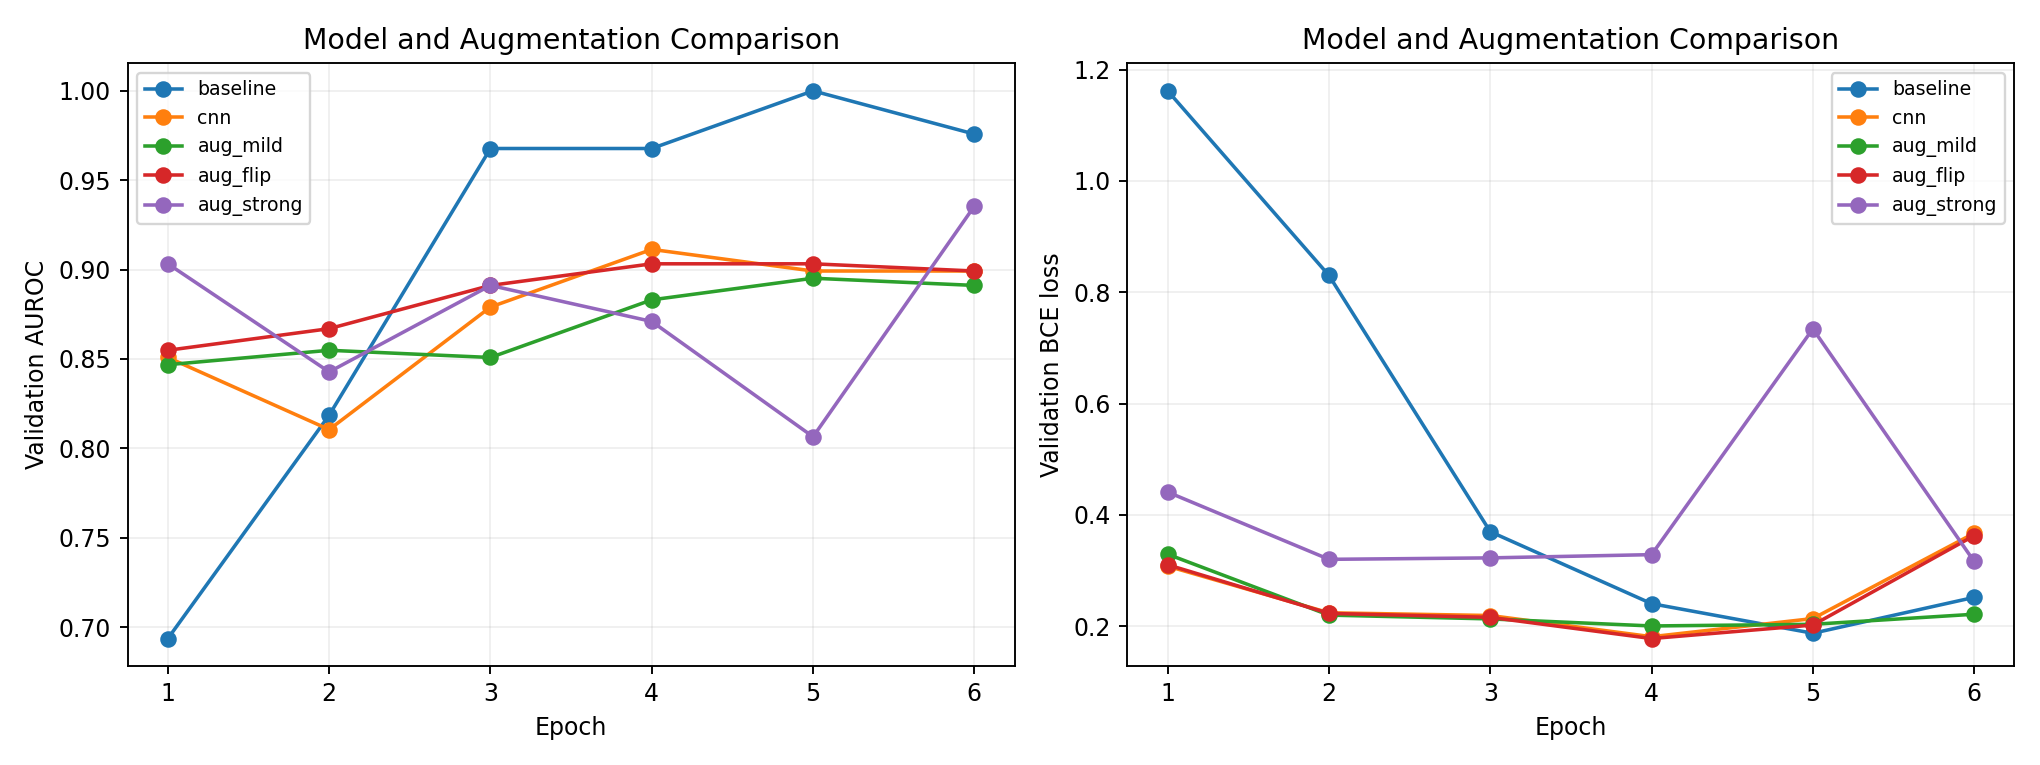

In [ ]:
# [ADDED] Summary table and plots, based ONLY on validation (no test data).
assert RUN_ALL_EXPERIMENTS and len(experiment_results) == 16, 'Run all 16 experiments first.'
columns = ['name','architecture','width','dropout','lr','batch_size','optimizer','epochs',
           'weight_decay','scheduler','augmentation','best_epoch','val_auroc',
           'val_balanced_accuracy','val_accuracy','val_sensitivity','val_specificity']
table = []
for r in experiment_results:
    row = {k:r[k] for k in columns if k in r}
    for k in ['auroc','balanced_accuracy','accuracy','sensitivity','specificity']:
        row['val_'+k] = r['validation'][k]
    table.append(row)
with open(RESULTS_DIR/'experiment_table.csv','w',newline='',encoding='utf-8') as fh:
    writer=csv.DictWriter(fh, fieldnames=columns)
    writer.writeheader()
    writer.writerows(table)

print('Experiment                         val_AUROC   val_bal_acc    val_acc')
for r in experiment_results:
    v = r['validation']
    print(f'{r["name"]:32s} {v["auroc"]:9.4f} {v["balanced_accuracy"]:12.4f} {v["accuracy"]:10.4f}')

fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
for name in ['baseline','cnn','aug_mild','aug_flip','aug_strong']:
    result = next(r for r in experiment_results if r['name'] == name)
    axs[0].plot([h['epoch'] for h in result['history']],
                [h['val_auroc'] for h in result['history']], marker='o', label=name)
    axs[1].plot([h['epoch'] for h in result['history']],
                [h['val_loss'] for h in result['history']], marker='o', label=name)
axs[0].set(xlabel='Epoch',ylabel='Validation AUROC',title='Model and Augmentation Comparison')
axs[1].set(xlabel='Epoch',ylabel='Validation BCE loss',title='Model and Augmentation Comparison')
for ax in axs:
    ax.legend(fontsize=8); ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(RESULTS_DIR/'comparison_curves.png', dpi=170)
plt.show()


## [ADDED] Best configuration, test set evaluation, and interpretation

Pick the **best configuration by validation AUROC**, using validation balanced accuracy as tie-break. The test set is inspected **only after** selection; its performance is reported once for the selected configuration. Please do not select another model after seeing the test results. Note that with 4 NORMAL images in the validation set, AUROC and especially specificity are highly uncertain.

In [ ]:
# [ADDED] FINAL EVALUATE — corresponds to teacher's original Cell 25.
# Never use test metrics for hyperparameter selection.
selected = sorted(
    experiment_results,
    key=lambda r: (r['validation']['auroc'], r['validation']['balanced_accuracy']),
    reverse=True
)[0]
print('Selected by validation only:', selected['name'])
print('Configuration:', {k:selected[k] for k in
      ['architecture','width','dropout','lr','batch_size','optimizer','weight_decay',
       'epochs','scheduler','augmentation']})

# Build the model architecture for the selected checkpoint.
model = make_model(selected['architecture'],selected['width'],selected['dropout']).to(device)
model_path = RESULTS_DIR/(selected['name']+'.pth')
avg_test_loss, avg_test_acc, final_test_metrics = evaluate(
    model, device, model_path, test_loader, criterion)
print('Selected TEST metrics (held-out, once):', final_test_metrics)

summary = dict(
    selected_name=selected['name'],
    selection_rule='maximum val AUROC, tie break by val balanced accuracy',
    selected_validation=selected['validation'],
    selected_test=final_test_metrics,
    n_train=len(train_dataset), n_val=len(val_dataset), n_test=len(test_dataset),
    caveat='Highly imbalanced small subset with only 26 NORMAL images; filename-group patient IDs unverified'
)
(RESULTS_DIR/'selected_model_summary.json').write_text(json.dumps(summary,indent=2),encoding='utf-8')


Selected by validation only: baseline
Configuration: {'architecture': 'mlp', 'width': 64, 'dropout': 0.5, 'lr': 0.001, 'batch_size': 32, 'optimizer': 'adam', 'weight_decay': 0.001, 'epochs': 6, 'scheduler': 'none', 'augmentation': 'none'}
Model weights loaded successfully: /mnt/data/results_annotated/baseline.pth
Test accuracy: 97.98%; balanced accuracy: 75.00%; AUROC: 0.9921
Confusion matrix: TN=2 FP=2 FN=0 TP=95
Selected TEST metrics (held-out, once): {'accuracy': 0.9797979797979798, 'balanced_accuracy': 0.75, 'sensitivity': 1.0, 'specificity': 0.5, 'auroc': 0.9921052631578947, 'average_precision': 0.9996675654702265, 'tn': 2, 'fp': 2, 'fn': 0, 'tp': 95, 'loss': 0.19146525483540813, 'n': 99}


## [ADDED] What to write in the analysis report (do not invent results)

1. **Data 15%**: show `original_counts`, the inferred-group split summary and `split_manifest.json`; explain why the original provided test set could not be used.
2. **Optimization 15%**: compare `baseline`, `lr_low`, `lr_high`, `batch_16`, `optimizer_sgd`, `optimizer_adamw` using saved validation curves and `experiment_table.csv`.
3. **Schedule 15%**: compare `epochs_12`, `schedule_cosine`, `weightdecay_0`, `weightdecay_high` to baseline. The training accuracy uses a **resampled training stream**, so explain that train/validation accuracy gaps are not directly prevalence-matched.
4. **Architecture 20%**: compare `mlp_small`, `mlp_drop_low` with MLP baseline; compare CNN and explain its inductive bias. Do not infer a universal CNN vs MLP ranking from this small single split.
5. **Augmentation 20%**: compare `cnn`, `aug_mild`, `aug_flip`, `aug_strong`. For chest X-ray, mild rotation/translation/contrast often preserve diagnostic information better than strong crop/rotation; horizontal flipping can affect laterality and left/right anatomical markers.
6. **Conclusion 15%**: report chosen hyperparameters from the FINAL EVALUATE cell, test confusion matrix, limitations (4 NORMAL samples per val/test and possible source shortcuts), and next steps (additional normal cases, patient-level IDs, multi-seed evaluation, external test set, calibration).

**Never claim this experiment is suitable for actual diagnosis.** The test set comes from re-splitting the original ZIP, not an external source. A high accuracy with poor specificity is not a clinically reliable classifier.